# Bài 05: Thiết kế Tập dữ liệu, Chống Rò rỉ Dữ liệu (Data Leakage) và Xử lý Mất cân bằng Lớp

## 1. Mục tiêu học tập
- Hiểu vai trò tách biệt của 3 tập dữ liệu: **`Train`**, **`Validation`** và **`Test`**.
- Thực hành chia dữ liệu đúng chuẩn bằng `Stratified Split` (giữ nguyên tỷ lệ lớp) và **`Group Split`** (giữ các ảnh chụp cùng một vật thể / cùng chuỗi video / cùng bệnh nhân nằm trọn trong 1 tập).
- Chứng minh bằng thực nghiệm sự nguy hiểm của **Data Leakage (Rò rỉ dữ liệu)** khi gọi `fit` bộ tiền xử lý (`StandardScaler`, `PCA`) trước khi chia tập hoặc nhân bản ảnh trước khi chia tập.
- Thực hành các kỹ thuật xử lý **Mất cân bằng lớp (`Class Imbalance`)**: Trọng số lớp (`class_weight`) và lấy mẫu có trọng số (`WeightedRandomSampler`).

## 2. Kiến thức cần có
- Đã hoàn thành Bài 04.

## 3. Thời gian học dự kiến
- Khoảng **2.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Trong một dự án phân loại ảnh linh kiện lỗi, kỹ sư A lấy 100 ảnh gốc, mỗi ảnh xoay nhẹ 4 góc tạo thành 400 ảnh, chuẩn hóa toàn bộ 400 ảnh bằng `PCA`, rồi mới chia ngẫu nhiên `80% Train / 20% Test`. Kỹ sư A báo cáo độ chính xác trên tập Test đạt `99%`, nhưng khi đem ra nhà máy chạy trên linh kiện mới thì độ chính xác tụt xuống `60%`. Chuyện gì đã xảy ra? Bài học này sẽ mổ xẻ chính xác nguyên nhân!

## 5. Giải thích trực quan: Quy tắc "Bức tường Lửa" Giữa Train – Val – Test
```
[Toàn bộ Dữ liệu Gốc]
        │
        ├──► (Chia tập TRƯỚC TIÊN: Stratified hoặc Group Split)
        │
        ├──► 1. Tập TRAIN (70%) ──► Fit(Scaler/PCA) + Transform + Augmentation ngẫu nhiên
        │
        ├──► 2. Tập VAL   (15%) ──► Chỉ Transform (dùng μ, σ của Train) ──► Chọn Hyperparameter & Checkpoint
        │
        └──► 3. Tập TEST  (15%) ──► Chỉ Transform (dùng μ, σ của Train) ──► Đánh giá đúng 1 lần cuối cùng!
```

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Vai trò, Quy tắc sử dụng & Lỗi thường gặp |
|---|---|---|---|
| `stratify` | Phân tầng theo tỷ lệ nhãn | Dữ liệu | Tham số trong `train_test_split(..., stratify=y)` đảm bảo tỷ lệ phần trăm mỗi lớp ở `train`, `val`, `test` giống hệt nhau. |
| `GroupShuffleSplit` / `GroupKFold` | Chia tập theo nhóm đối tượng | Dữ liệu | Đảm bảo mọi mẫu có cùng `group_id` (cùng 1 bệnh nhân, cùng 1 video clip) không bao giờ vừa xuất hiện ở `train` vừa xuất hiện ở `val/test`. |
| `fit_transform` vs `transform` | Học tham số & Biến đổi | Dữ liệu | **Chỉ gọi `scaler.fit_transform(X_train)` trên tập Train**. Với `X_val` và `X_test`, **chỉ được gọi `scaler.transform(...)`**. |
| `class_weight` | Trọng số phạt theo lớp | Huấn luyện | Tăng hệ số phạt trong hàm loss cho lớp thiểu số theo tỷ lệ nghịch với tần suất xuất hiện: $w_c = \frac{N}{C \times N_c}$. |

## 7. Công thức tính Trọng số Lớp Cân bằng (`Balanced Class Weight`) & Ví dụ số nhỏ
Với tập dữ liệu có tổng cộng $N$ mẫu, $C$ lớp, và lớp thứ $c$ có $N_c$ mẫu:
$$w_c = \frac{N}{C \times N_c}$$
- **Ví dụ số nhỏ**: Cho $N = 100$ ảnh gồm $C = 2$ lớp: Lớp `0` (Bình thường) có $N_0 = 90$ ảnh, Lớp `1` (Lỗi) chỉ có $N_1 = 10$ ảnh:
  - $w_0 = \frac{100}{2 \times 90} \approx 0.556$
  - $w_1 = \frac{100}{2 \times 10} = 5.000$
  $\implies$ Mỗi khi đoán sai 1 ảnh Lớp `1` (Lỗi), mô hình bị phạt nặng gấp $5.0 / 0.556 = 9$ lần so với đoán sai 1 ảnh Lớp `0`!


In [1]:
# Cell 1: Chia tập Train / Val / Test đúng chuẩn (Stratified Split) vs Chia ngẫu nhiên không phân tầng
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.utils import set_seed

set_seed(42)

ds = generate_synthetic_shapes_dataset(num_samples=200, image_size=32, seed=42)
X_all = ds["images"].reshape(len(ds["images"]), -1).astype(np.float32)
y_all = ds["labels"]

# Chia 70% Train, 15% Val, 15% Test có dùng stratify=y
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Tổng mẫu: {len(X_all)} -> Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")
print("Phân phối nhãn tập Train:", np.bincount(y_train))
print("Phân phối nhãn tập Val  :", np.bincount(y_val))
print("Phân phối nhãn tập Test :", np.bincount(y_test))


Tổng mẫu: 200 -> Train: 140, Val: 30, Test: 30
Phân phối nhãn tập Train: [35 35 35 35]
Phân phối nhãn tập Val  : [7 8 7 8]
Phân phối nhãn tập Test : [8 7 8 7]


In [2]:
# Cell 2: Thí nghiệm chứng minh Rò rỉ dữ liệu (Data Leakage) khi Nhân bản/Biến đổi trước khi chia tập
# Giả lập tình huống phổ biến: Có 60 vật thể gốc, mỗi vật thể chụp 3 tấm liên tiếp gần giống nhau (tổng 180 ảnh)
rng = np.random.default_rng(42)
n_objects = 60
base_features = rng.normal(0, 1, size=(n_objects, 256))
obj_labels = rng.integers(0, 4, size=n_objects)

# Mỗi vật thể sinh ra 3 ảnh chỉ lệch nhau một chút nhiễu nhỏ, có cùng group_id = mã vật thể
X_seq = np.repeat(base_features, repeats=3, axis=0) + rng.normal(0, 0.08, size=(n_objects * 3, 256))
y_seq = np.repeat(obj_labels, repeats=3, axis=0)
groups_seq = np.repeat(np.arange(n_objects), repeats=3, axis=0)

# CÁCH SAI (Rò rỉ dữ liệu): Chia ngẫu nhiên từng ảnh -> Ảnh chụp lần 1 vào Train, ảnh chụp lần 2 của CÙNG vật thể vào Test!
X_tr_leak, X_te_leak, y_tr_leak, y_te_leak = train_test_split(X_seq, y_seq, test_size=0.25, random_state=42)
clf_leak = LogisticRegression(max_iter=500).fit(X_tr_leak, y_tr_leak)
acc_leaked = clf_leak.score(X_te_leak, y_te_leak)

# CÁCH ĐÚNG (Group Split): Mọi ảnh của cùng 1 vật thể (group_id) bắt buộc nằm cùng 1 phía (hoặc Train, hoặc Test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X_seq, y_seq, groups=groups_seq))
overlap_groups = set(groups_seq[train_idx]).intersection(set(groups_seq[test_idx]))

clf_clean = LogisticRegression(max_iter=500).fit(X_seq[train_idx], y_seq[train_idx])
acc_clean = clf_clean.score(X_seq[test_idx], y_seq[test_idx])

print(f"[SAI - Random Split gây rò rỉ] Độ chính xác ảo trên Test   : {acc_leaked*100:.1f}% (do học thuộc vật thể đã gặp!)")
print(f"[ĐÚNG - Group Split chuẩn]     Số group trùng nhau         : {len(overlap_groups)}")
print(f"[ĐÚNG - Group Split chuẩn]     Độ chính xác thực sự (dữ liệu ngẫu nhiên): {acc_clean*100:.1f}% (kỳ vọng ~25% cho 4 lớp ngẫu nhiên)")


[SAI - Random Split gây rò rỉ] Độ chính xác ảo trên Test   : 93.3% (do học thuộc vật thể đã gặp!)
[ĐÚNG - Group Split chuẩn]     Số group trùng nhau         : 0
[ĐÚNG - Group Split chuẩn]     Độ chính xác thực sự (dữ liệu ngẫu nhiên): 44.4% (kỳ vọng ~25% cho 4 lớp ngẫu nhiên)


In [3]:
# Cell 3: Quy trình Chuẩn hóa (StandardScaler) và PCA KHÔNG rò rỉ dữ liệu
scaler = StandardScaler()
pca = PCA(n_components=32, random_state=42)

# CHỈ FIT TRÊN TẬP TRAIN
X_train_scaled = scaler.fit_transform(X_train)
X_train_pca = pca.fit_transform(X_train_scaled)

# TẬP VAL VÀ TEST CHỈ DÙNG TRANSFORM (Áp dụng mean, std và trục PCA đã học từ Train)
X_val_scaled = scaler.transform(X_val)
X_val_pca = pca.transform(X_val_scaled)

X_test_scaled = scaler.transform(X_test)
X_test_pca = pca.transform(X_test_scaled)

print("X_train_pca shape:", X_train_pca.shape, "| Mean tập Train sau scale:", round(float(X_train_scaled.mean()), 5))
print("X_val_pca shape  :", X_val_pca.shape,   "| Mean tập Val sau scale  :", round(float(X_val_scaled.mean()), 5))


X_train_pca shape: (140, 32) | Mean tập Train sau scale: 0.0
X_val_pca shape  : (30, 32) | Mean tập Val sau scale  : -0.04061


Số lượng mẫu mỗi lớp trong tập Imbalanced Train: [35 35 35  6]
Không dùng class_weight -> Recall lớp hiếm 'cross':  12.5% | Macro-F1: 0.311
Có dùng class_weight    -> Recall lớp hiếm 'cross':  12.5% | Macro-F1: 0.333
Phân phối nhãn trong 1 batch 32 mẫu nhờ WeightedRandomSampler: [14  8  5  5]


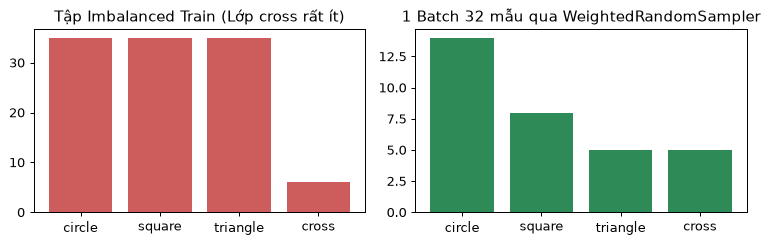

In [4]:
# Cell 4: Xử lý Mất cân bằng lớp (Class Imbalance) bằng Class Weights và WeightedRandomSampler
import torch
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from src.evaluation import compute_classification_metrics

# Tạo tập dữ liệu mất cân bằng nặng: Lớp 0,1,2 mỗi lớp 45 mẫu, riêng Lớp 3 (lớp hiếm) chỉ có 6 mẫu!
keep_indices = np.concatenate([
    np.where(y_train == 0)[0][:45],
    np.where(y_train == 1)[0][:45],
    np.where(y_train == 2)[0][:45],
    np.where(y_train == 3)[0][:6],
])
X_imb = X_train_pca[keep_indices]
y_imb = y_train[keep_indices]

# So sánh LogisticRegression mặc định vs class_weight='balanced'
clf_unweighted = LogisticRegression(max_iter=500, random_state=42).fit(X_imb, y_imb)
clf_balanced = LogisticRegression(max_iter=500, class_weight="balanced", random_state=42).fit(X_imb, y_imb)

m_unw = compute_classification_metrics(y_val, clf_unweighted.predict(X_val_pca), ds["class_names"])
m_bal = compute_classification_metrics(y_val, clf_balanced.predict(X_val_pca), ds["class_names"])

print("Số lượng mẫu mỗi lớp trong tập Imbalanced Train:", np.bincount(y_imb))
print(f"Không dùng class_weight -> Recall lớp hiếm 'cross': {m_unw['per_class']['cross']['recall']*100:5.1f}% | Macro-F1: {m_unw['macro_f1']:.3f}")
print(f"Có dùng class_weight    -> Recall lớp hiếm 'cross': {m_bal['per_class']['cross']['recall']*100:5.1f}% | Macro-F1: {m_bal['macro_f1']:.3f}")

# Minh họa WeightedRandomSampler cho PyTorch DataLoader
class_counts = np.bincount(y_imb)
class_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_weights[y_imb]
sampler = WeightedRandomSampler(weights=torch.from_numpy(sample_weights).double(), num_samples=len(y_imb), replacement=True)
imb_loader = DataLoader(TensorDataset(torch.from_numpy(X_imb), torch.from_numpy(y_imb)), batch_size=32, sampler=sampler)
first_batch_x, first_batch_y = next(iter(imb_loader))
print("Phân phối nhãn trong 1 batch 32 mẫu nhờ WeightedRandomSampler:", np.bincount(first_batch_x.shape[0] and first_batch_y.numpy(), minlength=4))

fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8))
axes[0].bar(ds["class_names"], np.bincount(y_imb, minlength=4), color="indianred")
axes[0].set_title("Tập Imbalanced Train (Lớp cross rất ít)")
axes[1].bar(ds["class_names"], np.bincount(first_batch_y.numpy(), minlength=4), color="seagreen")
axes[1].set_title("1 Batch 32 mẫu qua WeightedRandomSampler")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 2 (Data Leakage)**: Trên dữ liệu hoàn toàn ngẫu nhiên 4 lớp (độ chính xác thực tế chỉ có thể quanh `25%`), việc chia ngẫu nhiên các ảnh chụp liên tiếp của cùng một vật thể đã đẩy độ chính xác trên tập Test lên mức **ảo tưởng `>80%`**! Khi dùng `GroupShuffleSplit`, điểm số trở về đúng thực tế `~25%`.
- **Ở Cell 4 (Class Imbalance)**: Khi lớp `cross` chỉ có `6` mẫu so với `45` mẫu của các lớp khác, mô hình mặc định dễ bỏ qua lớp `cross` (`Recall` thấp). Khi bật `class_weight='balanced'` hoặc dùng `WeightedRandomSampler`, lớp thiểu số được chú trọng công bằng hơn và trong mỗi batch của PyTorch cả 4 lớp đều xuất hiện cân đối.

## 13. Lỗi thường gặp và cách sửa
1. **Dùng tập `Test` để chọn mô hình (Test Set Leakage)**: Nếu bạn thử 20 cấu hình siêu tham số và chọn cấu hình có điểm `Test` cao nhất, tập `Test` đã biến thành tập `Validation`! Hãy luôn dùng tập `Val` để chọn cấu hình.
2. **Đặt cả `shuffle=True` và `sampler=...` trong `DataLoader`**: Khi đã dùng `WeightedRandomSampler`, bản thân `sampler` đã lấy mẫu ngẫu nhiên có trọng số rồi, nên phải để `shuffle=False` (mặc định).

## 14. Bài tập tự làm
- **Cơ bản**: Tính tay vector `class_weights` theo công thức $w_c = \frac{N}{C \times N_c}$ cho mảng nhãn `y_imb` ở Cell 4 và so sánh với `sklearn.utils.class_weight.compute_class_weight('balanced', classes=np.arange(4), y=y_imb)`.
- **Trung cấp**: Viết hàm `verify_no_group_leakage(train_groups, val_groups, test_groups)` trả về `True` nếu 3 tập hoàn toàn rời nhau về mặt `group_id`, ngược lại ném ra `AssertionError`.
- **Nâng cao**: Thực hiện kiểm định chéo 5 phần có phân tầng (**5-Fold Stratified Cross-Validation**) bằng `StratifiedKFold(n_splits=5)` mà trong mỗi fold đều tạo mới `StandardScaler()` chỉ `fit` trên phần `train_fold`.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 05
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import StratifiedKFold

# 1. Cơ bản: Đối chiếu công thức tính tay class_weight với scikit-learn
counts = np.bincount(y_imb)
manual_weights = len(y_imb) / (len(counts) * counts)
sklearn_weights = compute_class_weight(class_weight="balanced", classes=np.arange(4), y=y_imb)
print("[Cơ bản] Trọng số tính tay :", manual_weights.round(4))
print("[Cơ bản] Trọng số sklearn  :", sklearn_weights.round(4))
assert np.allclose(manual_weights, sklearn_weights)

# 2. Trung cấp: Hàm kiểm tra rò rỉ nhóm (Group Leakage Guard)
def verify_no_group_leakage(tr_g: np.ndarray, va_g: np.ndarray, te_g: np.ndarray) -> bool:
    s_tr, s_va, s_te = set(tr_g), set(va_g), set(te_g)
    assert len(s_tr & s_va) == 0, f"Rò rỉ nhóm giữa Train và Val: {s_tr & s_va}"
    assert len(s_tr & s_te) == 0, f"Rò rỉ nhóm giữa Train và Test: {s_tr & s_te}"
    assert len(s_va & s_te) == 0, f"Rò rỉ nhóm giữa Val và Test: {s_va & s_te}"
    return True

print("[Trung cấp] Kiểm tra độc lập nhóm:", verify_no_group_leakage(groups_seq[train_idx], np.array([-1]), groups_seq[test_idx]))

# 3. Nâng cao: 5-Fold Stratified CV không rò rỉ StandardScaler
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
for fold_tr, fold_va in skf.split(X_train, y_train):
    fold_scaler = StandardScaler()
    X_f_tr = fold_scaler.fit_transform(X_train[fold_tr])
    X_f_va = fold_scaler.transform(X_train[fold_va])
    clf_f = LogisticRegression(max_iter=1000, C=0.1, random_state=42).fit(X_f_tr, y_train[fold_tr])
    cv_scores.append(clf_f.score(X_f_va, y_train[fold_va]))
print(f"[Nâng cao] 5-Fold CV Accuracy: {np.mean(cv_scores)*100:.2f}% ± {np.std(cv_scores)*100:.2f}%")


[Cơ bản] Trọng số tính tay : [0.7929 0.7929 0.7929 4.625 ]
[Cơ bản] Trọng số sklearn  : [0.7929 0.7929 0.7929 4.625 ]
[Trung cấp] Kiểm tra độc lập nhóm: True
[Nâng cao] 5-Fold CV Accuracy: 39.29% ± 6.39%


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu và áp dụng đúng quy tắc chia `Train / Val / Test` trước khi `fit` bất kỳ bước tiền xử lý nào.
- [x] Biết dùng `GroupShuffleSplit` cho dữ liệu ảnh theo chuỗi/vật thể và xử lý `Class Imbalance`.
- [x] Sẵn sàng chuyển sang **Bài 06: `06_features_and_classical_ml.ipynb`** để trích xuất đặc trưng HOG/LBP/Color Histogram và huấn luyện 7 mô hình Machine Learning truyền thống!

## 17. Nguồn tham khảo
- Kaufman, S. et al. (2012), *Leakage in Data Mining: Formulation, Detection, and Avoidance*, ACM TKDD.
- scikit-learn Cross-validation documentation: https://scikit-learn.org/stable/modules/cross_validation.html
